# m08 - Two Suitability Products: Cross-Source Transfer and Downscaling Validation

The warehouse holds two independent suitability products for six crops (rice, maize, cassava, soybean, oil palm, sugarcane):

* **GAEZ v5** index, ~9 km native resolution (164 distinct pixels cover Banten).
* **Global Crop Suitability 2024** (GCS), ~1 km native resolution, a different model and different inputs.

Questions:

1. **A. Agreement.** How well do the two products agree at the 1 km cell level and at the GAEZ-pixel level?
2. **B. Learnability.** Is GCS easier or harder to learn from the 14 physical drivers than GAEZ, and does it leak as much under random K-fold?
3. **C. Transfer.** A surrogate trained on one product, scored against the other (rank correlation, pixel-grouped CV).
4. **D. Downscaling validation.** GAEZ is constant inside a 9 km pixel, so the surrogate's variation *within* a pixel is
   invented by the model. Does it match the variation GCS (an independent 1 km product) shows within the same pixels?
5. **E. Where do the products disagree?**

GCS values are multiplied by 10,000 so both products live on the same 0-10,000 scale. 114 cells without a GCS value are dropped.

In [1]:
import sys
from pathlib import Path

# Make exp_lib importable no matter where the notebook is launched from.
HERE = next(p for p in (Path.cwd(), Path.cwd() / "scripts" / "modeling") if (p / "exp_lib.py").exists())
sys.path.insert(0, str(HERE))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import exp_lib as E
from threadpoolctl import threadpool_limits

threadpool_limits(E.N_JOBS)   # BLAS/OpenMP in this kernel stay within the same CPU budget as the worker pool
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160)

In [2]:
df_all = E.load_table()
GC = E.GCS_CROPS
ok = df_all[E.gcs_cols()].notna().all(axis=1)
df = df_all[ok].reset_index(drop=True)
print(f"{len(df)} of {len(df_all)} cells have all six GCS values; {df['pix'].nunique()} native GAEZ pixels")
gaez = {c: df[f"gaez_index_{c}"].to_numpy() for c in GC}
gcs = {c: df[f"gcs2024_{c}"].to_numpy() * 10_000 for c in GC}

9219 of 9333 cells have all six GCS values; 163 native GAEZ pixels


## A. Agreement between the products

In [3]:
rows = []
for c in GC:
    cell_rho = E.spearman(gaez[c], gcs[c])
    pm_g = pd.Series(gaez[c]).groupby(df["pix"]).mean(); pm_c = pd.Series(gcs[c]).groupby(df["pix"]).mean()
    rows.append({"crop": c, "spearman_cell": cell_rho, "pearson_cell": np.corrcoef(gaez[c], gcs[c])[0, 1],
                 "spearman_pixel_mean": E.spearman(pm_g.to_numpy(), pm_c.to_numpy()),
                 "gaez_mean": gaez[c].mean(), "gcs_mean": gcs[c].mean(),
                 "gcs_within_pixel_share_of_variance": (gcs[c] - pd.Series(gcs[c]).groupby(df["pix"]).transform("mean")).var() / gcs[c].var()})
agree = pd.DataFrame(rows).set_index("crop")
E.save_table(agree.round(4), "m08_agreement", index=True)
agree.round(3)

,spearman_cell,pearson_cell,spearman_pixel_mean,gaez_mean,gcs_mean,gcs_within_pixel_share_of_variance
crop,,,,,,
rice,0.781,0.761,0.687,3003.768,6291.085,0.135
maize,0.435,0.429,0.379,1301.539,2980.012,0.247
cassava,0.359,0.485,0.349,3932.872,8424.220,0.183
soybean,-0.174,-0.104,-0.223,1724.859,1485.257,0.377
oilpalm,0.591,0.622,0.566,4374.198,6616.829,0.162
sugarcane,0.796,0.716,0.592,2320.696,7322.331,0.090


## B. Learnability of each product (5 models, random vs spatial CV)

In [4]:
targets = {**{f"gaez:{c}": gaez[c] for c in GC}, **{f"gcs:{c}": gcs[c] for c in GC}}
MODELS = ["ridge", "knn", "et", "hgb", "xgb"]
SCHEMES = ["random", "block10", "pixel"]
res, oof = E.run_grid(df, targets, MODELS, SCHEMES, n_repeats=2, keep_oof=True)
res[["source", "crop"]] = res["target"].str.split(":", expand=True)
E.save_table(res.drop(columns="target"), "m08_learnability_raw")
tab = res.groupby(["source", "model", "scheme"])["r2"].mean().unstack("scheme")[SCHEMES]
tab["leakage_gap"] = tab["random"] - tab["pixel"]
E.save_table(tab.round(4), "m08_learnability", index=True)
tab.round(3)

360 tasks (5 models x 12 targets x 3 schemes x 2 repeats), 14 features


done in 69 s


scheme        random  block10  pixel  leakage_gap
source model                                     
gaez   et      0.971    0.892  0.844        0.127
       hgb     0.952    0.880  0.830        0.122
       knn     0.918    0.796  0.751        0.167
       ridge   0.636    0.593  0.588        0.048
       xgb     0.944    0.877  0.827        0.117
gcs    et      0.919    0.776  0.794        0.126
       hgb     0.894    0.752  0.772        0.122
       knn     0.856    0.692  0.723        0.133
       ridge   0.562    0.505  0.525        0.037
       xgb     0.879    0.747  0.765        0.115

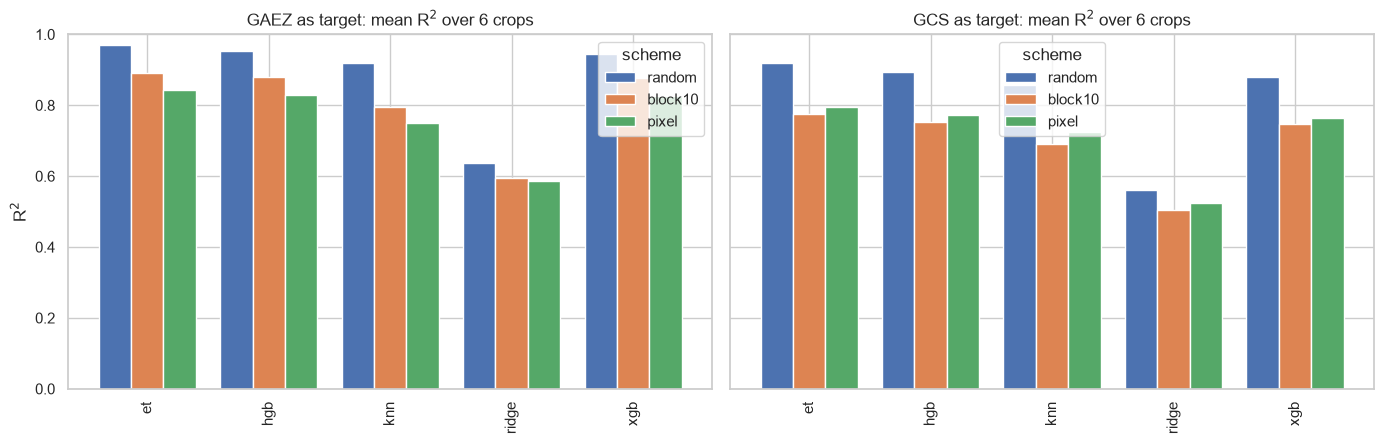

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
for ax, src in zip(axes, ["gaez", "gcs"]):
    tab.loc[src][SCHEMES].plot.bar(ax=ax, width=0.8)
    ax.set(title=f"{src.upper()} as target: mean R$^2$ over 6 crops", xlabel="", ylabel="R$^2$", ylim=(0, 1))
plt.tight_layout()
E.save_fig(fig, "m08_learnability")
plt.show()

## C. Cross-source transfer (pixel CV, hist-boosting and extra-trees surrogates)
Spearman rho between each surrogate's out-of-fold predictions and each product.

In [6]:
rows = []
for m in ["hgb", "et"]:
    for c in GC:
        pg = np.mean([oof[(m, f"gaez:{c}", "pixel", r)] for r in range(2)], axis=0)
        pc = np.mean([oof[(m, f"gcs:{c}", "pixel", r)] for r in range(2)], axis=0)
        rows.append({"model": m, "crop": c,
                     "raw GAEZ vs GCS": E.spearman(gaez[c], gcs[c]),
                     "GAEZ-surrogate vs GAEZ": E.spearman(pg, gaez[c]),
                     "GAEZ-surrogate vs GCS": E.spearman(pg, gcs[c]),
                     "GCS-surrogate vs GCS": E.spearman(pc, gcs[c]),
                     "GCS-surrogate vs GAEZ": E.spearman(pc, gaez[c])})
tr = pd.DataFrame(rows)
E.save_table(tr.round(4), "m08_transfer", index=False)
tr[tr.model == "hgb"].set_index("crop").drop(columns="model").round(3)

,raw GAEZ vs GCS,GAEZ-surrogate vs GAEZ,GAEZ-surrogate vs GCS,GCS-surrogate vs GCS,GCS-surrogate vs GAEZ
crop,,,,,
rice,0.781,0.916,0.844,0.953,0.806
maize,0.435,0.904,0.488,0.837,0.528
cassava,0.359,0.913,0.364,0.781,0.445
soybean,-0.174,0.904,-0.185,0.803,-0.245
oilpalm,0.591,0.909,0.607,0.898,0.618
sugarcane,0.796,0.901,0.815,0.896,0.848


In [7]:
mean_tr = tr.groupby("model").mean(numeric_only=True).round(3)
mean_tr

,raw GAEZ vs GCS,GAEZ-surrogate vs GAEZ,GAEZ-surrogate vs GCS,GCS-surrogate vs GCS,GCS-surrogate vs GAEZ
model,,,,,
et,0.464,0.914,0.496,0.879,0.51
hgb,0.464,0.908,0.489,0.861,0.50


## D. Downscaling validation: within-pixel agreement

For every cell take its departure from the mean of its native GAEZ pixel. GAEZ itself has (almost) no such variation, so the
surrogate's within-pixel pattern is a prediction. GCS provides an independent 1 km reference for the same quantity.

Baselines: the best *single raw feature*'s within-pixel departure (sign-agnostic, so the strongest of 14 trivial predictors).

In [8]:
def demean(v):
    return v - pd.Series(v).groupby(df["pix"]).transform("mean").to_numpy()

feat_anom = {f: demean(df[f].fillna(df[f].median()).to_numpy()) for f in E.feature_columns()}
rows = []
for c in GC:
    ref = demean(gcs[c])
    best_feat, best_rho = max(((f, abs(E.spearman(a, ref))) for f, a in feat_anom.items()), key=lambda t: t[1])
    row = {"crop": c, "best single feature": best_feat, "|rho| best single feature": best_rho,
           "within-pixel rho(raw GAEZ, GCS)": E.spearman(demean(gaez[c]), ref)}
    for m in ["hgb", "et", "xgb"]:
        pg = np.mean([oof[(m, f"gaez:{c}", "pixel", r)] for r in range(2)], axis=0)
        pc = np.mean([oof[(m, f"gcs:{c}", "pixel", r)] for r in range(2)], axis=0)
        row[f"{m}: GAEZ-surrogate"] = E.spearman(demean(pg), ref)
        row[f"{m}: GCS-surrogate"] = E.spearman(demean(pc), ref)
    rows.append(row)
within = pd.DataFrame(rows).set_index("crop")
E.save_table(within.round(4), "m08_within_pixel", index=True)
within.round(3)

,best single feature,|rho| best single feature,"within-pixel rho(raw GAEZ, GCS)",hgb: GAEZ-surrogate,hgb: GCS-surrogate,et: GAEZ-surrogate,et: GCS-surrogate,xgb: GAEZ-surrogate,xgb: GCS-surrogate
crop,,,,,,,,,
rice,elevation_mean_m,0.557,0.151,0.386,0.664,0.404,0.692,0.394,0.665
maize,bio1_temp_mean_c,0.165,-0.008,0.073,0.485,0.061,0.561,0.073,0.472
cassava,bio12_precip_annual_mm,0.168,0.039,0.132,0.393,0.127,0.460,0.122,0.380
soybean,bio12_precip_annual_mm,0.204,-0.074,-0.080,0.415,-0.070,0.479,-0.067,0.411
oilpalm,elevation_mean_m,0.315,0.084,0.238,0.633,0.233,0.687,0.244,0.614
sugarcane,bio12_precip_annual_mm,0.256,0.131,0.261,0.420,0.290,0.501,0.250,0.386


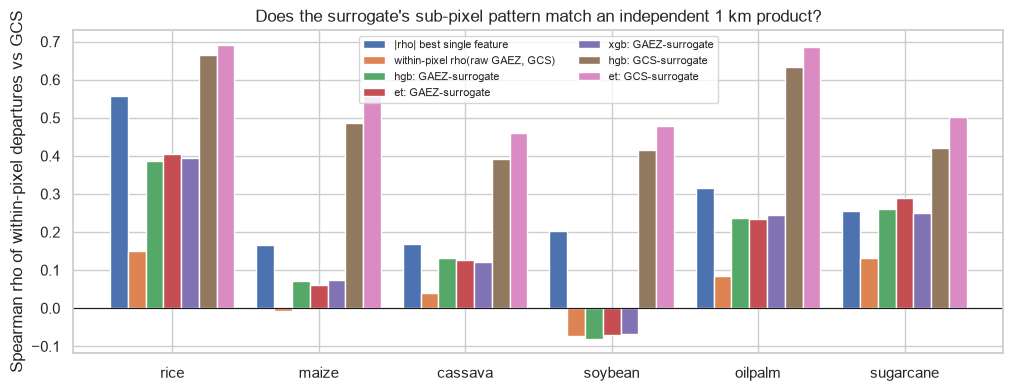

In [9]:
cols = ["|rho| best single feature", "within-pixel rho(raw GAEZ, GCS)", "hgb: GAEZ-surrogate", "et: GAEZ-surrogate", "xgb: GAEZ-surrogate",
        "hgb: GCS-surrogate", "et: GCS-surrogate"]
fig, ax = plt.subplots(figsize=(12, 4.2))
within[cols].plot.bar(ax=ax, width=0.85)
ax.axhline(0, color="k", lw=0.8)
ax.set(ylabel="Spearman rho of within-pixel departures vs GCS", xlabel="", title="Does the surrogate's sub-pixel pattern match an independent 1 km product?")
ax.legend(fontsize=8, ncol=2)
plt.xticks(rotation=0)
E.save_fig(fig, "m08_within_pixel")
plt.show()

## E. Where do the two products disagree?
Percentile rank of the GAEZ surrogate minus percentile rank of GCS (positive = GAEZ rates the cell higher than GCS does).

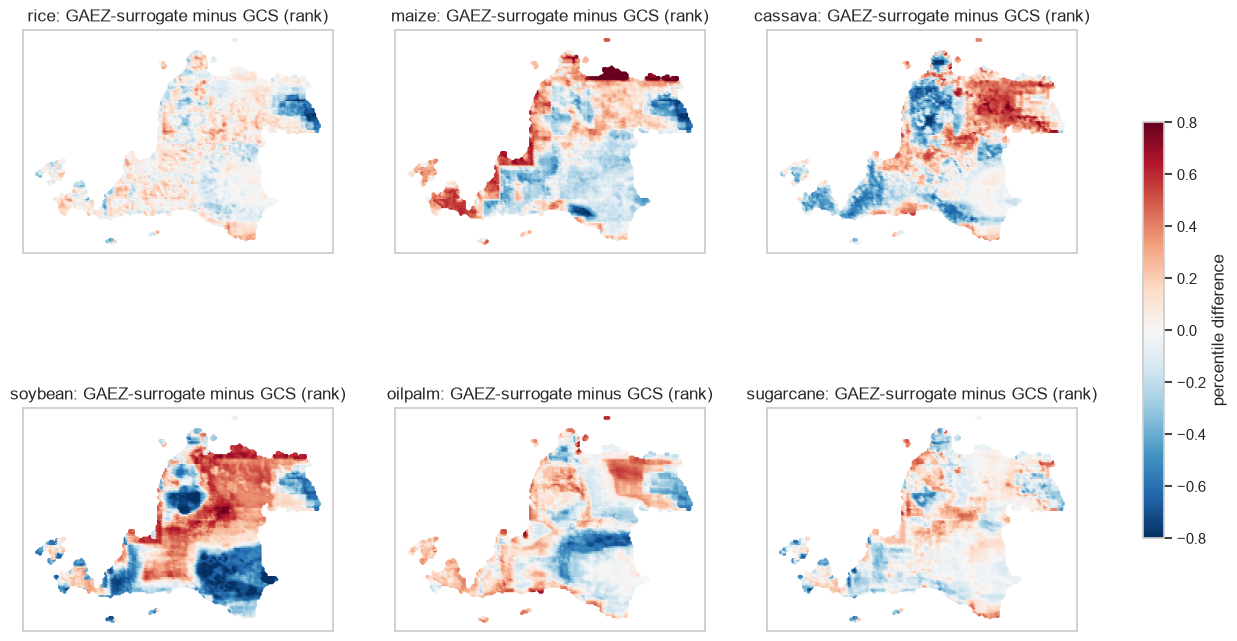

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, c in zip(axes.ravel(), GC):
    pg = np.mean([oof[("hgb", f"gaez:{c}", "pixel", r)] for r in range(2)], axis=0)
    d = pd.Series(pg).rank(pct=True).to_numpy() - pd.Series(gcs[c]).rank(pct=True).to_numpy()
    sc = ax.scatter(df["lon"], df["lat"], c=d, s=3, cmap="RdBu_r", vmin=-0.8, vmax=0.8)
    ax.set(title=f"{c}: GAEZ-surrogate minus GCS (rank)", aspect="equal"); ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(sc, ax=axes, shrink=0.6, label="percentile difference")
E.save_fig(fig, "m08_disagreement_maps")
plt.show()